# Learning a DC Motor Model with a Neural Network

This notebook tests whether a feedforward neural network can learn the behaviour of a physics-based DC motor model.

The reference motor is a FAULHABER 0615 permanent-magnet DC micromotor. Its behaviour was simulated in MATLAB/Simulink across different voltage and load conditions.

The simulated data is used to train a neural network in Python, which is then evaluated against the original Simulink model.

A linear regression model is also used as a baseline. This comparison was included because it was not initially obvious whether the neural network was learning something substantially different from a simpler linear model.

### Workflow

Physics model → Simulated data → Neural network → Evaluation → Linear regression comparison

## 1. Setup & Dataset

Load the libraries required for data handling, preprocessing, machine learning, neural networks, and visualization.

The dataset contains time-series observations generated from multiple Simulink simulations of the motor.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
# Load the simulated motor dataset
dataset = pd.read_csv('../data/motor_dataset.csv')
dataset.head()

,Voltage,Load Torque,Time,Current,Speed
0,0.1,0.0,0.000000e+00,1.000000e-10,0.000000
1,0.1,0.0,5.000378e-07,3.584455e-03,0.002957
2,0.1,0.0,1.000076e-06,6.667816e-03,0.006291
3,0.1,0.0,1.500114e-06,9.320134e-03,0.009450
4,0.1,0.0,2.000151e-06,1.169753e-02,0.012462


In [3]:
# Inspect the size, structure, and basic statistics of the dataset
print(dataset.shape)
dataset.info()
print(dataset.describe())

(15706, 5)
<class 'pandas.DataFrame'>
RangeIndex: 15706 entries, 0 to 15705
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Voltage      15706 non-null  float64
 1   Load Torque  15706 non-null  float64
 2   Time         15706 non-null  float64
 3   Current      15706 non-null  float64
 4   Speed        15706 non-null  float64
dtypes: float64(5)
memory usage: 613.6 KB
            Voltage   Load Torque          Time       Current         Speed
count  15706.000000  15706.000000  15706.000000  1.570600e+04  15706.000000
mean       0.831440     -0.000073      0.053786  1.190024e-01   4091.323094
std        0.422323      0.000061      0.060186  9.846438e-02   5219.281066
min        0.100000     -0.000245      0.000000  1.000000e-10      0.000000
25%        0.500000     -0.000114      0.000024  3.529385e-02      6.353306
50%        0.800000     -0.000059      0.019592  8.180185e-02   1417.090246
75%        1.200000     

In [4]:
# Identify individual simulation runs.
# Time resets to zero whenever a new Simulink simulation begins.
dataset['Run'] = (dataset['Time'].diff()<0).cumsum()
dataset.head()

,Voltage,Load Torque,Time,Current,Speed,Run
0,0.1,0.0,0.000000e+00,1.000000e-10,0.000000,0
1,0.1,0.0,5.000378e-07,3.584455e-03,0.002957,0
2,0.1,0.0,1.000076e-06,6.667816e-03,0.006291,0
3,0.1,0.0,1.500114e-06,9.320134e-03,0.009450,0
4,0.1,0.0,2.000151e-06,1.169753e-02,0.012462,0


In [5]:
# create a normalized load feature
# Express load torque as a fraction of the voltage-dependent stall torque used in the simulations.
dataset['Load Fraction'] = dataset['Load Torque'].abs()/(0.245e-3* dataset['Voltage']/1.5)
dataset.head()

,Voltage,Load Torque,Time,Current,Speed,Run,Load Fraction
0,0.1,0.0,0.000000e+00,1.000000e-10,0.000000,0,0.0
1,0.1,0.0,5.000378e-07,3.584455e-03,0.002957,0,0.0
2,0.1,0.0,1.000076e-06,6.667816e-03,0.006291,0,0.0
3,0.1,0.0,1.500114e-06,9.320134e-03,0.009450,0,0.0
4,0.1,0.0,2.000151e-06,1.169753e-02,0.012462,0,0.0


## 2. Prepare the Data

The neural network will use voltage, load torque, normalized load, and time to predict motor current and speed.

The data is split by complete simulation runs so that observations from the same simulation do not appear in both the training and test sets.

The input and output variables are then standardized to make them easier for the neural network to learn.

In [6]:
# Define the features used by the model and the outputs it will predict
input_features = ['Voltage', 'Load Torque', 'Load Fraction', 'Time']
output_features = ['Current', 'Speed']

In [7]:
# Keep complete simulation runs together when creating the training and test sets.
run_conditions = dataset[['Run', 'Voltage', 'Load Torque']].drop_duplicates('Run')

train_runs, test_runs = train_test_split(run_conditions, test_size = 0.2, random_state = 42)

train_run_ids = train_runs['Run'].values
test_run_ids = test_runs['Run'].values

train_dataset = dataset[dataset['Run'].isin(train_run_ids)].copy()
test_dataset = dataset[dataset['Run'].isin(test_run_ids)].copy()

X_train = train_dataset[input_features]
y_train = train_dataset[output_features]

X_test = test_dataset[input_features]
y_test = test_dataset[output_features]

In [8]:
# Standardize inputs and outputs using statistics from the training data only, preventing information leakage from the test set.
input_scaler = StandardScaler()
output_scaler = StandardScaler()

X_train_scaled = input_scaler.fit_transform(X_train)
X_test_scaled = input_scaler.transform(X_test)

y_train_scaled = output_scaler.fit_transform(y_train)
y_test_scaled = output_scaler.transform(y_test)

## 3. Build & Train the Neural Network

The first learned motor model is a feedforward neural network.

It receives four inputs:

- Voltage
- Load Torque
- Load Fraction
- Time

and predicts:

- Current
- Speed

The two hidden layers use ReLU activation, allowing the network to represent nonlinear relationships between the inputs and motor outputs.

During training, Keras performs forward propagation, calculates the loss, uses backpropagation to calculate gradients, and updates the network weights using Adam.

In [9]:
# Build the feedforward neural network
model = keras.Sequential([keras.Input(shape=(4,)),
                          layers.Dense(32, activation='relu'),
                          layers.Dense(32, activation='relu'),
                          layers.Dense(2)])

In [10]:
# Configure the training process
model.compile(optimizer = 'adam', loss = 'mse', metrics = ['mae'])

The validation split is taken from the final 20% of the training data before training begins. Because the simulation runs are ordered in the dataset, this validation subset may not represent the full range of operating conditions evenly.

The held-out test runs are kept separate and are used for the final evaluation.

In [11]:
# Train the network while keeping 20% of the training data aside for validation.
history = model.fit(X_train_scaled, y_train_scaled, validation_split = 0.2, 
                    epochs = 100, batch_size = 64, verbose = 1)

Epoch 1/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.4521 - mae: 0.5350 - val_loss: 1.3446 - val_mae: 1.0427
Epoch 2/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.2672 - mae: 0.3800 - val_loss: 1.0362 - val_mae: 0.8985
Epoch 3/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1942 - mae: 0.3151 - val_loss: 0.8270 - val_mae: 0.7829
Epoch 4/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1594 - mae: 0.2769 - val_loss: 0.7091 - val_mae: 0.7035
Epoch 5/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1441 - mae: 0.2548 - val_loss: 0.6568 - val_mae: 0.6655
Epoch 6/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1360 - mae: 0.2416 - val_loss: 0.6240 - val_mae: 0.6413
Epoch 7/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1308 - mae: 0.2321 - val_loss: 0.5991 - val_mae: 0.6205
Epoch 8/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1273 - mae: 0.2251 - val_loss: 0.5800 - val_mae: 0.6050
Epoch 9/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms

## 4. Evaluate the Neural Network

The trained network is evaluated on simulation runs that were not used during training.

Predictions are converted back to the original physical scale before calculating MAE and RMSE.

The goal is to determine how closely the learned model reproduces the behaviour of the Simulink motor.

In [12]:
# Generate predictions for the unseen test runs
y_pred_scaled = model.predict(X_test_scaled)
# Convert predictions back to the original physical units
y_pred = output_scaler.inverse_transform(y_pred_scaled)

101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


In [13]:
# Calculate prediction errors for current and speed
current_mae = mean_absolute_error(y_test['Current'], y_pred[:,0])
speed_mae = mean_absolute_error(y_test['Speed'], y_pred[:,1])

current_rmse = np.sqrt(mean_squared_error(y_test['Current'], y_pred[:,0]))
speed_rmse = np.sqrt(mean_squared_error(y_test['Speed'], y_pred[:,1]))

print(f'Current MAE: {current_mae}')
print(f'Current RMSE: {current_rmse}')

print(f'Speed MAE: {speed_mae}')
print(f'Speed RMSE: {speed_rmse}')

Current MAE: 0.024355385402566803
Current RMSE: 0.04838349395641801
Speed MAE: 317.92286118391985
Speed RMSE: 629.8512220028903


Text(0.5, 1.0, 'NN Speed Prediction vs Simulink')

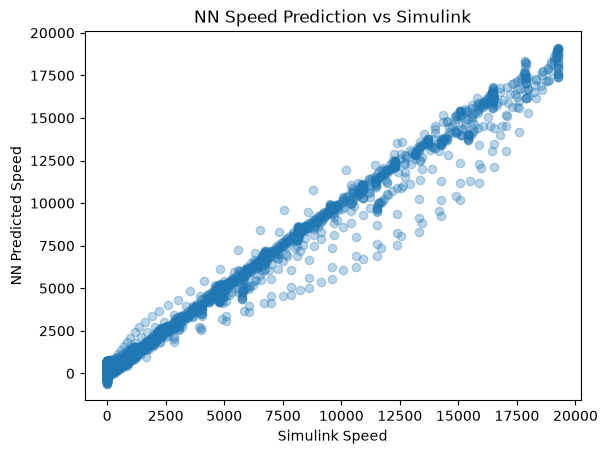

In [14]:
# Compare predicted speed with the speed produced by Simulink
plt.scatter(y_test['Speed'], y_pred[:,1], alpha=0.3)
plt.xlabel('Simulink Speed')
plt.ylabel('NN Predicted Speed')
plt.title('NN Speed Prediction vs Simulink')

## 5. Linear Regression Baseline

The neural network is more complex than a linear regression model, so it is useful to test whether that additional complexity actually provides an advantage.

This comparison was motivated by a simple question:

> Is the neural network really doing something different, or could a linear model reproduce the motor behaviour just as well?

The linear model is trained using exactly the same training and test data as the neural network.

In [15]:
# Train a linear regression model using the same inputs and training data
linear_model = LinearRegression()
linear_model.fit(X_train_scaled,y_train_scaled)

# Generate predictions and convert them back to physical units
linear_predictions_scaled = linear_model.predict(X_test_scaled)
linear_predictions = output_scaler.inverse_transform(linear_predictions_scaled)

# Evaluate the linear regression model using the same metrics
linear_current_mae = mean_absolute_error(y_test["Current"],linear_predictions[:, 0])
linear_speed_mae = mean_absolute_error(y_test["Speed"],linear_predictions[:, 1])
linear_current_rmse = np.sqrt(mean_squared_error(y_test["Current"],linear_predictions[:, 0]))
linear_speed_rmse = np.sqrt(mean_squared_error(y_test["Speed"],linear_predictions[:, 1]))

print("Current MAE:", linear_current_mae)
print("Current RMSE:", linear_current_rmse)
print("Speed MAE:", linear_speed_mae)
print("Speed RMSE:", linear_speed_rmse)

Current MAE: 0.06254173819813783
Current RMSE: 0.0809812507947232
Speed MAE: 3533.354972568272
Speed RMSE: 4446.125432410948


## 6. Results & Next Step

This notebook compares a feedforward neural network with a linear regression baseline for predicting DC motor current and speed from simulated operating conditions.

Both models are evaluated on complete simulation runs held out from training. Their prediction errors provide a basis for comparing the two approaches.

The final performance comparison will be confirmed after the project is rerun and the evaluation metrics are regenerated.

This feedforward model predicts outputs at individual time points. It does not explicitly maintain a recurrent state across a sequence.

**Next:** develop dynamic models that use sequential motor data to predict the motor's behaviour over time.